The dataset chosen for this project is the UsArrest, which shows the names of the states in the United States where arrest were made.
The dataset set shows murder rates per state within the United States, how many assults committed per state, urban population in each state and the number of rape cases per state

The program begins by import all relevant libraries needed to analyse and visualise the dataset

In [1]:
import pandas as pd

# For Box-Cox Transformation
from scipy import stats

# Plotting modules
import seaborn as sns

import matplotlib.pyplot as plt
import numpy as np

# Scaling modules
from sklearn.preprocessing import MinMaxScaler, StandardScaler

np.random.seed(0)

df = pd.read_csv('UsArrests.csv')
df.head()

,City,Murder,Assault,UrbanPop,Rape
0,Alabama,13.2,236,58,21.2
1,Alaska,10.0,263,48,44.5
2,Arizona,8.1,294,80,31.0
3,Arkansas,8.8,190,50,19.5
4,California,9.0,276,91,40.6


1. The dataset chosen is the US arrests dataset. First, let us clean the dataset ready for analysis. As you can see there Rape and Murder column are in floating point notation. UrbanPo are in integers, states usually have hundreds of thousand to millions of citizens. As part of cleaning the data need to convert Rape and Murder columns into integer notations for mathematical operations

In [2]:
df['Murder'] = df["Murder"].round().astype(int)
df['Rape'] = df['Rape'].round().astype(int)

df.head()

,City,Murder,Assault,UrbanPop,Rape
0,Alabama,13,236,58,21
1,Alaska,10,263,48,44
2,Arizona,8,294,80,31
3,Arkansas,9,190,50,20
4,California,9,276,91,41


2. Check the size of the dataset

In [3]:
# Return the number rows and columns of the DataFrame
df.shape

(50, 5)

3. Always check missing values

In [4]:
# get the number of missing data points per column
missing_values_count = df.isnull().sum()

# Look at the number of missing points per column
missing_values_count[0:5]

City        0
Murder      0
Assault     0
UrbanPop    0
Rape        0
dtype: int64

4. Compare the average murder rate per state

In [5]:
# Calculates and displays which state has the highest and lowest assault cases per state using the idxmax() and idxmin() methods
highest_murder_per_state = df.loc[df["Murder"].idxmax()]
lowest_murder_per_state = df.loc[df["Murder"].idxmin()]
print(highest_murder_per_state)
print(lowest_murder_per_state)


City        Georgia
Murder           17
Assault         211
UrbanPop         60
Rape             26
Name: 9, dtype: object
City        North Dakota
Murder                 1
Assault               45
UrbanPop              44
Rape                   7
Name: 33, dtype: object


5. Compare average assault per state

In [6]:
# Calculates and displays state with the highest and lowest assault cases per state using idxmax() and idxmin() methods.
highest_assault_per_state = df.loc[df["Assault"].idxmax()]
lowest_assault_per_state = df.loc[df["Assault"].idxmin()]
print(highest_assault_per_state)
print(lowest_assault_per_state)

City        North Carolina
Murder                  13
Assault                337
UrbanPop                45
Rape                    16
Name: 32, dtype: object
City        North Dakota
Murder                 1
Assault               45
UrbanPop              44
Rape                   7
Name: 33, dtype: object


6. Compare the average UrbanPo per state

In [8]:
# Calculates and displays the states with highest and lowest urban population using the idxmax() and idxmin() methods
highest_UrbanPop_per_state = df.loc[df["UrbanPop"].idxmax()]
lowest_UrbanPop_per_state = df.loc[df["UrbanPop"].idxmin()]
print(highest_UrbanPop_per_state)
print(lowest_UrbanPop_per_state)

City        California
Murder               9
Assault            276
UrbanPop            91
Rape                41
Name: 4, dtype: object
City        Vermont
Murder            2
Assault          48
UrbanPop         32
Rape             11
Name: 44, dtype: object


7. Compare the average rape cases per state


In [9]:
# Calculates and display the states with the highest and lowest rape cases per state using the idxmax() and idxmin() methods
highest_rape_per_state = df.loc[df["Rape"].idxmax()]
lowest_rape_per_state = df.loc[df["Rape"].idxmin()]
print(highest_rape_per_state)
print(lowest_rape_per_state)


City        Nevada
Murder          12
Assault        252
UrbanPop        81
Rape            46
Name: 27, dtype: object
City        North Dakota
Murder                 1
Assault               45
UrbanPop              44
Rape                   7
Name: 33, dtype: object


8. Which state has the highest murder rate

In [10]:
# Calculates and displays state with highest murder rate using idxmax() method
state_highest_murder_rate = df.loc[df["Murder"].idxmax()]
print("State with highest murder rate is:")
print(state_highest_murder_rate["City"])


State with highest murder rate is:
Georgia


9. Which state has the highest assault rate

In [11]:
# Calculates and displays state with highest assault cases using idxmax() method
state_highest_assault = df.loc[df["Assault"].idxmax()]
print("State with the highest assault is: ")
print(state_highest_assault["City"])

State with the highest assault is: 
North Carolina


10. Which state has the highest Urban Population

In [12]:
# Calculates and displays state with highest population using idxmax() method
state_highest_population = df.loc[df["UrbanPop"].idxmax()]
print("State with the highest urban popupaltion is :")
print(state_highest_population["City"])

State with the highest urban popupaltion is :
California


11. Which state has the highest rape cases

In [13]:
# Calculates and displays state with highest rape cases using idxmax() method
state_highest_rape_cases = df.loc[df["Rape"].idxmax()]
print("State with the highest rape cases is ")
print(state_highest_rape_cases["City"])

State with the highest rape cases is 
Nevada


12. Which state has the lowest murder cases

In [14]:
# Calculates and displays state with the lowest murder rate using idxmin() method
state_lowest_murder_rate = df.loc[df["Murder"].idxmin()]
print("State with the lowest murder cases is ")
print(state_lowest_murder_rate["City"])

State with the lowest murder cases is 
North Dakota


13. Which state has the lowest assault cases

In [15]:
# Calculates and displays state with lowest assault rate using idxmin() method
state_assault_lowest = df.loc[df["Assault"].idxmin()]
print("State with the lowest assault cases is:")
print(state_assault_lowest["City"])

State with the lowest assault cases is:
North Dakota


14. Which city has the lowest Urban population

In [16]:
# Calculates and displays state with lowest urban population using idxmin() method
state_urban_lowest = df.loc[df["UrbanPop"].idxmin()]
print("State with the lowest urban population is: ")
print(state_urban_lowest["City"])

State with the lowest urban population is: 
Vermont


15. Which state has the lowest rape cases

In [17]:
# Calculates and display state with the lowest rape cases using idxmin() method
state_lowest_rape_cases = df.loc[df["Rape"].idxmin()]
print("State with lowest rape cases is ")
print(state_lowest_rape_cases["City"])

State with lowest rape cases is 
North Dakota


16. Plot states and murder rates

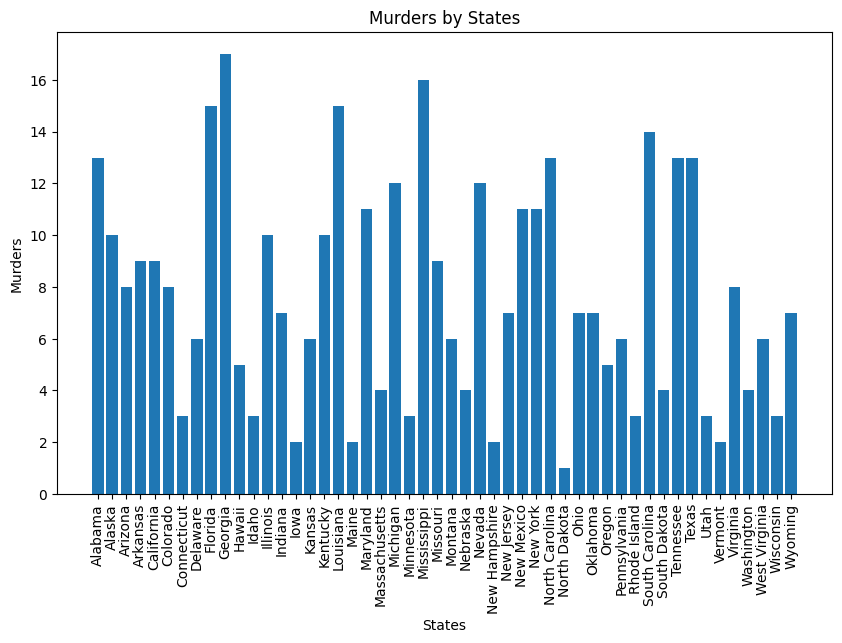

In [31]:
# Bar chart identifies and plots the states with the highest and lowest murder rates
plt.figure(figsize=(10, 6))

plt.bar(df["City"], df["Murder"])

# Labels and title
plt.xlabel("States")
plt.ylabel("Murders")
plt.title("Murders by States")

# Rotate city names
plt.xticks(rotation=90)

# Show plot
plt.show()

### Observation

The bar chart shows the distribution of murder rates across the different states in the US Arrests dataset. There is considerable variation in murder rates, with some states recording significantly higher rates than others. This indicates that violent crime is not evenly distributed across the country.

A few states stand out with noticeably higher murder rates, suggesting that these regions experienced higher levels of violent crime during the period represented by the dataset. Conversely, several states have relatively low murder rates, indicating lower levels of reported murders.

The chart effectively highlights differences between states and helps identify those with the highest and lowest murder rates. However, because there are many states displayed, the x-axis labels have been rotated by 90 degrees to improve readability. 

17. Plot Assaults and Cities

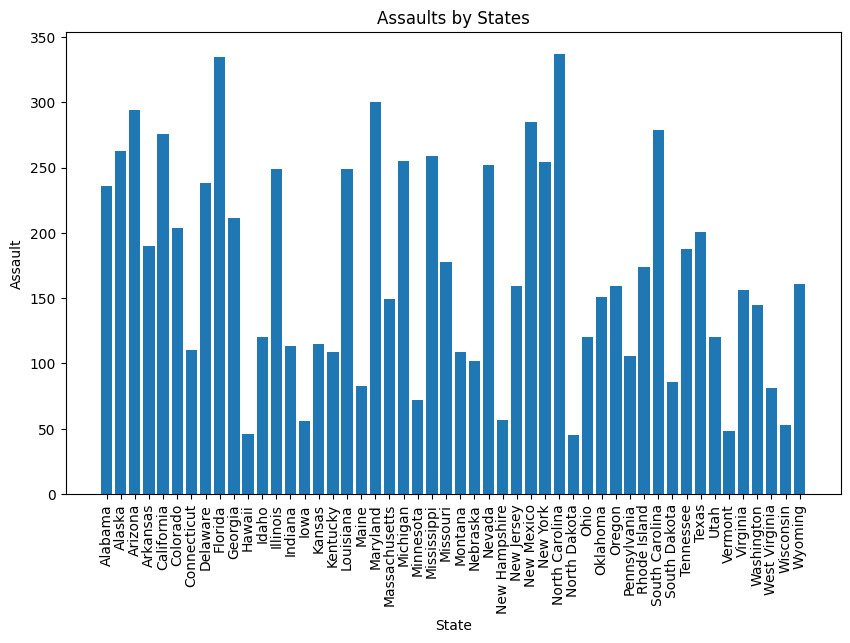

In [18]:
# Bar chart used to plot states with highest and lowest assault cases
plt.figure(figsize=(10, 6))

plt.bar(df["City"], df["Assault"])

# Labels and title
plt.xlabel("State")
plt.ylabel("Assault")
plt.title("Assaults by States")

# Rotate city names
plt.xticks(rotation=90)

# Show plot
plt.show()


### Observation

The bar chart illustrates the assault rates for each state in the US Arrests dataset. The results show considerable variation in assault rates across the states, indicating that some states experienced significantly higher levels of assault-related arrests than others.

Several states display noticeably higher assault rates, suggesting that violent crime involving assault was more prevalent in these areas during the period represented by the dataset. In contrast, other states recorded much lower assault rates, highlighting regional differences in crime patterns.

The rotation of the state names on the x-axis improves the readability of the chart by preventing label overlap, making it easier to compare the assault rates across all states. This visualization is useful for identifying states with unusually high or low assault rates and provides a basis for further analysis. 

18. Plot by Urban Population

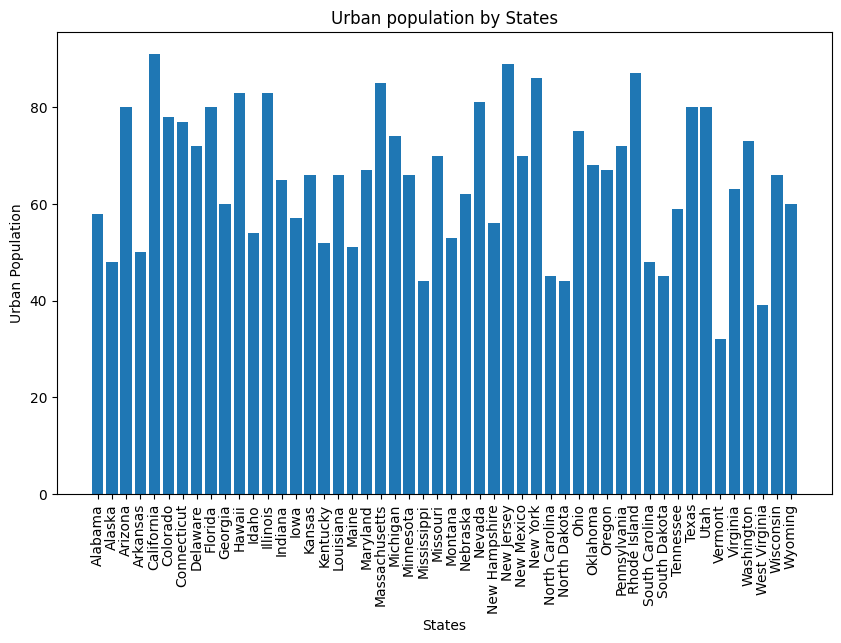

In [19]:
# Bar chart plots the states with the highest and lowest urban population
plt.figure(figsize=(10, 6))

plt.bar(df["City"], df["UrbanPop"])

# Labels and title
plt.xlabel("States")
plt.ylabel("Urban Population")
plt.title("Urban population by States")

# Rotate city names
plt.xticks(rotation=90)

# show plot
plt.show()

### Observation

The bar chart illustrates the percentage of the urban population for each state in the US Arrests dataset. The chart shows noticeable differences in the level of urbanisation across the states, with some states having a much larger proportion of their population living in urban areas than others.

States with higher urban population percentages are generally more urbanised, while those with lower percentages have a larger proportion of residents living in rural areas. This variation highlights the demographic differences between states and provides useful context for interpreting crime statistics.

Rotating the state names on the x-axis by 90 degrees improves the readability of the chart, allowing all state names to be displayed clearly without overlapping. The visualisation makes it easy to compare urban population percentages across all states and identify those with the highest and lowest levels of urbanisation.



19. Plot states and rape cases

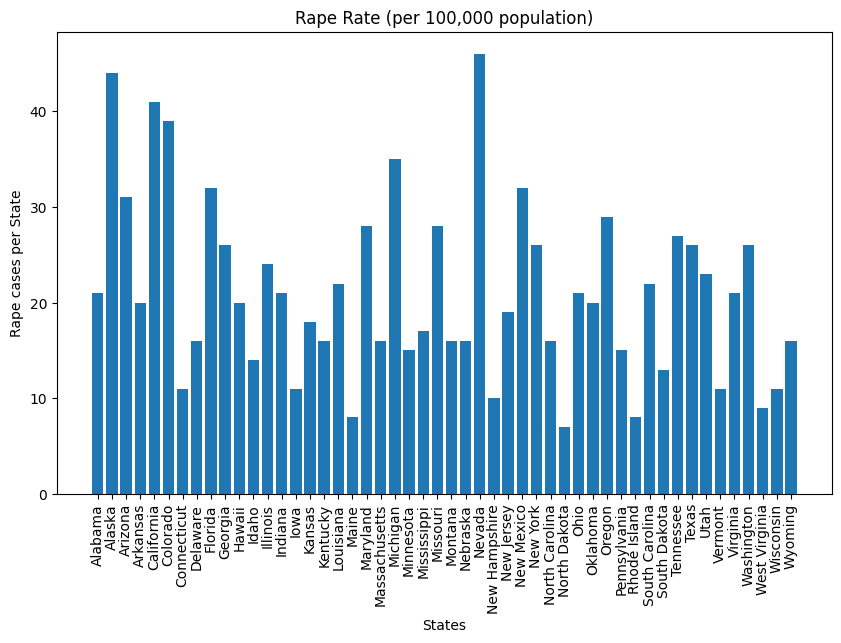

In [20]:
# Create bar chart
plt.figure(figsize=(10, 6))

plt.bar(df["City"], df["Rape"])

# Labels and title
plt.xlabel("States")
plt.ylabel("Rape cases per State")
plt.title("Rape Rate (per 100,000 population)")

# Rotate city names
plt.xticks(rotation=90)

# Show plot
plt.show()

### Observation

The bar chart displays the rape rates for each state in the US Arrests dataset, measured as the number of rape arrests per 100,000 population. The visualisation reveals substantial variation in rape rates across the states, indicating that some states experienced considerably higher rates than others during the period represented by the dataset.

A small number of states have noticeably higher rape rates, while several others record much lower values. These differences suggest that the incidence of rape-related arrests was not evenly distributed across the United States, highlighting regional variations in crime patterns.

The rotation of the state names on the x-axis by 90 degrees improves the readability of the chart by preventing the labels from overlapping. This allows for easier comparison of rape rates across all states and helps identify the states with the highest and lowest reported rates.



Histogram Distribution of Murder rates

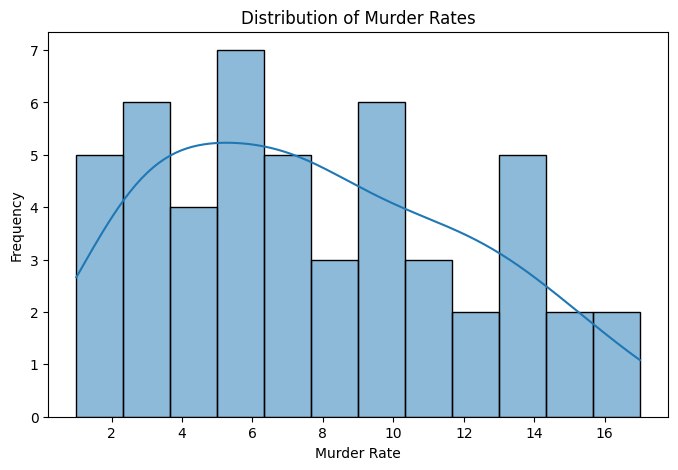

In [21]:
plt.figure(figsize=(8,5))
sns.histplot(df["Murder"], bins=12, kde=True)
plt.title("Distribution of Murder Rates")
plt.xlabel("Murder Rate")
plt.ylabel("Frequency")
plt.show()

### Observation

The histogram illustrates the distribution of murder rates across the states in the US Arrests dataset. The shape of the distribution shows that most states have relatively low to moderate murder rates, while only a few states exhibit very high murder rates. This indicates that higher murder rates are less common and may be considered outliers.

The Kernel Density Estimation (KDE) curve provides a smooth representation of the data distribution, making it easier to observe the overall pattern. The distribution appears to be positively (right) skewed, with a longer tail extending towards higher murder rates. This suggests that although the majority of states experienced lower murder rates, a small number of states had substantially higher rates.



Histogram distribution of Assault rates

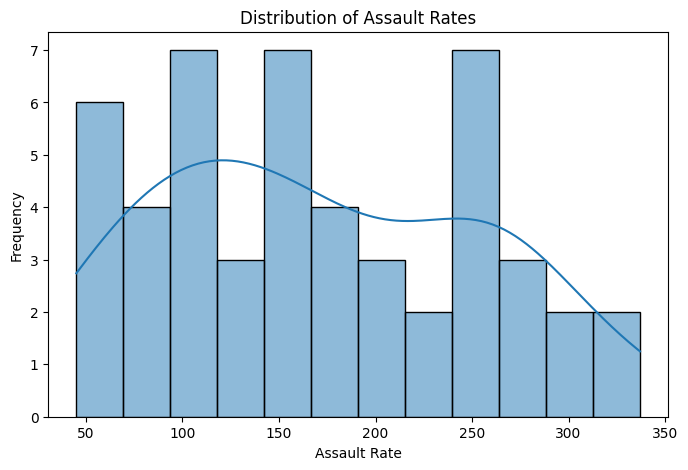

In [22]:
plt.figure(figsize=(8,5))
sns.histplot(df["Assault"], bins=12, kde=True)
plt.title("Distribution of Assault Rates")
plt.xlabel("Assault Rate")
plt.ylabel("Frequency")
plt.show()

### Observation

The histogram displays the distribution of assault rates across the states in the US Arrests dataset. The distribution indicates that assault rates vary considerably, with most states recording low to moderate assault rates and a smaller number of states experiencing much higher rates.

The Kernel Density Estimation (KDE) curve provides a smooth representation of the distribution and suggests that the data is positively (right) skewed. This means that while the majority of states have relatively lower assault rates, a few states have substantially higher assault rates, creating a longer tail on the right side of the distribution.



Histogram Distribution of Urban population rates

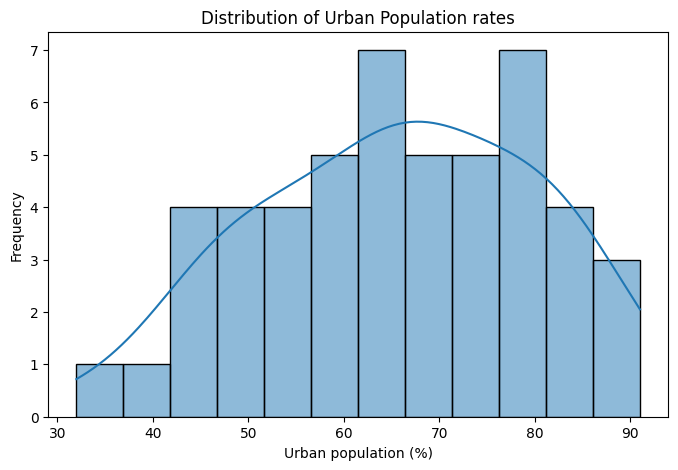

In [23]:
plt.figure(figsize=(8,5))
sns.histplot(df["UrbanPop"], bins=12, kde=True)
plt.title("Distribution of Urban Population rates")
plt.xlabel("Urban population (%)")
plt.ylabel("Frequency")
plt.show()

### Observation

The histogram illustrates the distribution of the percentage of the urban population across the states in the US Arrests dataset. The distribution shows that most states have moderate to high levels of urbanisation, while only a few states have relatively low urban population percentages.

The Kernel Density Estimation (KDE) curve provides a smooth representation of the data and indicates that the urban population percentages are more evenly distributed compared to the crime variables. The distribution appears to be approximately symmetric, with a slight concentration around the middle values, suggesting that many states have similar levels of urbanisation.

The histogram is useful for examining how urban population percentages are distributed across the dataset and identifying whether the data is concentrated within a particular range. Unlike the crime rate variables, the urban population variable does not appear to contain extreme outliers, indicating a more balanced spread of values.



Histogram Distribution by rape rates

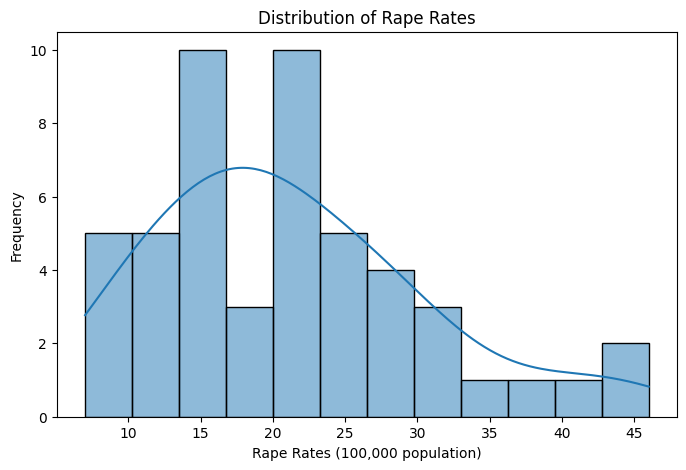

In [24]:
plt.figure(figsize=(8,5))
sns.histplot(df["Rape"], bins=12, kde=True)
plt.title("Distribution of Rape Rates")
plt.xlabel("Rape Rates (100,000 population)")
plt.ylabel("Frequency")
plt.show()

### Observation

The histogram illustrates the distribution of rape rates across the states in the US Arrests dataset. The distribution shows that most states have low to moderate rape rates, while a smaller number of states record comparatively higher rates. This indicates that higher rape rates are less common across the dataset.

The Kernel Density Estimation (KDE) curve provides a smooth representation of the distribution and suggests that the data is moderately positively (right) skewed. This means that the majority of states are clustered around lower rape rates, with relatively few states exhibiting substantially higher rates.

The histogram is useful for examining the frequency and spread of rape rates rather than comparing individual states. It highlights the overall distribution of the data and helps identify possible outliers or unusual observations that may require further investigation.

This visualisation provides valuable insight into the variability of rape rates across the states and serves as a foundation for additional exploratory analysis. 

Boxplot for Murder, Assault, UrbanPop and Rape

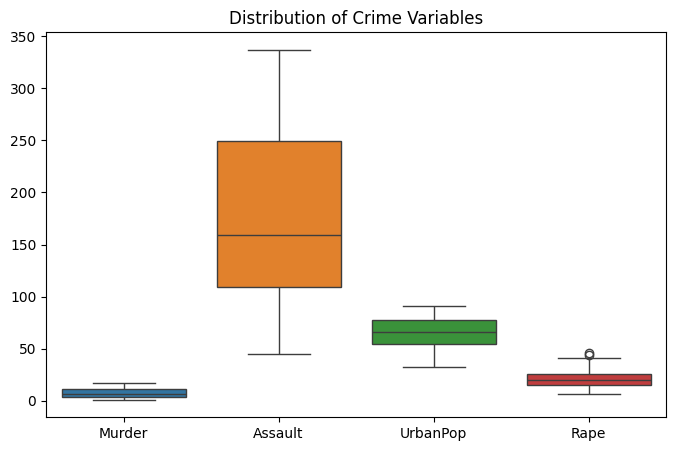

In [25]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df[["Murder","Assault","UrbanPop","Rape"]])
plt.title("Distribution of Crime Variables")
plt.show()

### Observation

The boxplot provides a summary of the distribution of the four variables in the US Arrests dataset: **Murder**, **Assault**, **UrbanPop**, and **Rape**. It displays the median, interquartile range (IQR), overall spread of the data, and any potential outliers for each variable, making it easy to compare their distributions.

The **Assault** variable exhibits the greatest variability, as indicated by its wider box and longer whiskers. This suggests that assault rates differ substantially across the states. In contrast, the **Murder** and **Rape** variables show a smaller spread, indicating less variation in their rates. The **UrbanPop** variable appears to have the most consistent distribution, with values concentrated within a narrower range.



Scatter plot Urban population vs Assault

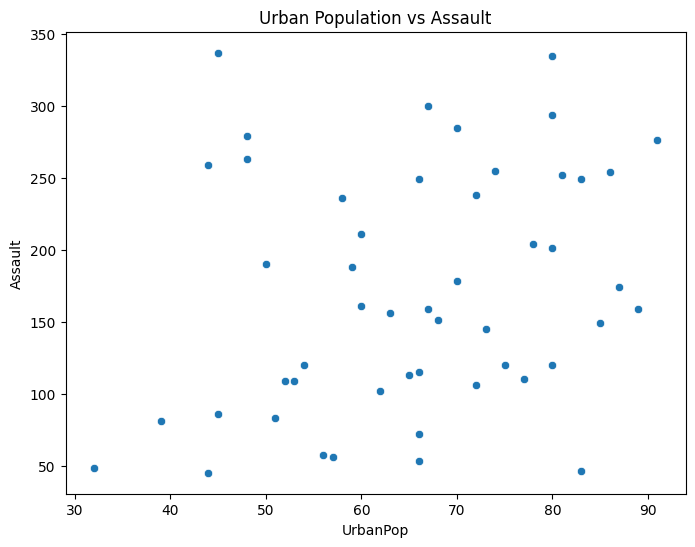

In [26]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df,
    x="UrbanPop",
    y="Assault"
)

plt.title("Urban Population vs Assault")
plt.show()

### Observation

The scatter plot illustrates the relationship between the percentage of the urban population and assault rates across the states in the US Arrests dataset. Each point on the graph represents a single state, with its position determined by its urban population percentage (x-axis) and assault rate (y-axis).

The distribution of points suggests that there is no strong linear relationship between urban population and assault rates. Although some states with higher urban population percentages also record relatively high assault rates, there are many exceptions, indicating that urbanisation alone does not fully explain differences in assault rates across states.

The spread of the data points demonstrates considerable variability in assault rates for states with similar levels of urbanisation. This implies that other social, economic, or demographic factors may also contribute to the observed differences in assault rates.



Scatter plot Murder vs Urban population

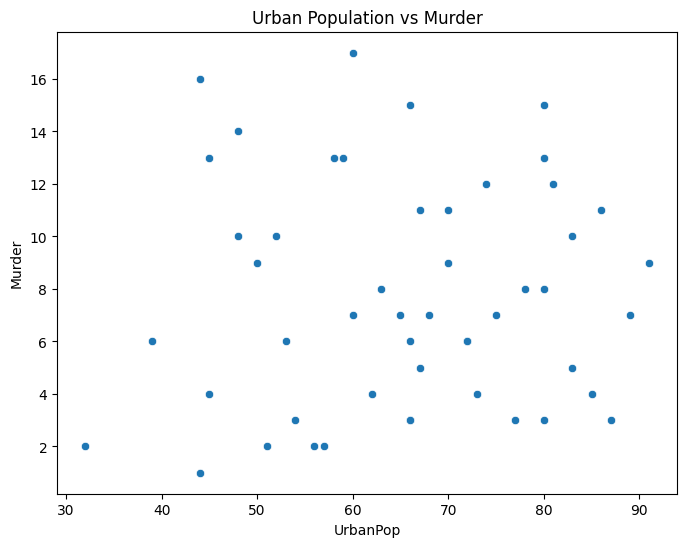

In [27]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df,
    x="UrbanPop",
    y="Murder"
)

plt.title("Urban Population vs Murder")
plt.show()

### Observation

The scatter plot illustrates the relationship between the percentage of the urban population and murder rates across the states in the US Arrests dataset. Each point represents a single state, with its position determined by its urban population percentage on the x-axis and its murder rate on the y-axis.

The distribution of the data points suggests that there is no strong linear relationship between urban population and murder rates. While some highly urbanised states have relatively high murder rates, others have moderate or low murder rates. Similarly, states with lower urban population percentages also display a wide range of murder rates. This indicates that urbanisation alone is not a reliable predictor of murder rates.

The wide spread of the points across the graph demonstrates considerable variability in murder rates among states with similar levels of urbanisation. This suggests that additional factors, such as socioeconomic conditions, law enforcement practices, education, or demographic characteristics, may influence murder rates.



Scatter plot Rape vs Urban population

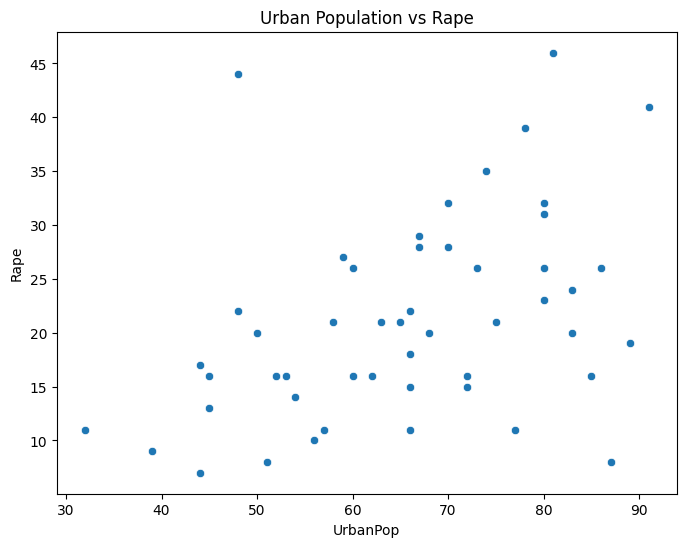

In [28]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df,
    x="UrbanPop",
    y="Rape"
)

plt.title("Urban Population vs Rape")
plt.show()

### Observation

The scatter plot illustrates the relationship between the percentage of the urban population and rape rates across the states in the US Arrests dataset. Each point represents a state, with the x-axis showing the percentage of the population living in urban areas and the y-axis representing the rape rate per 100,000 population.

The distribution of the data points indicates that there is no clear or strong linear relationship between urban population and rape rates. While some states with higher levels of urbanisation also exhibit higher rape rates, many states with similar urban population percentages have considerably different rape rates. This suggests that urbanisation alone does not account for the variation in rape rates across states.



Correlation heatmap

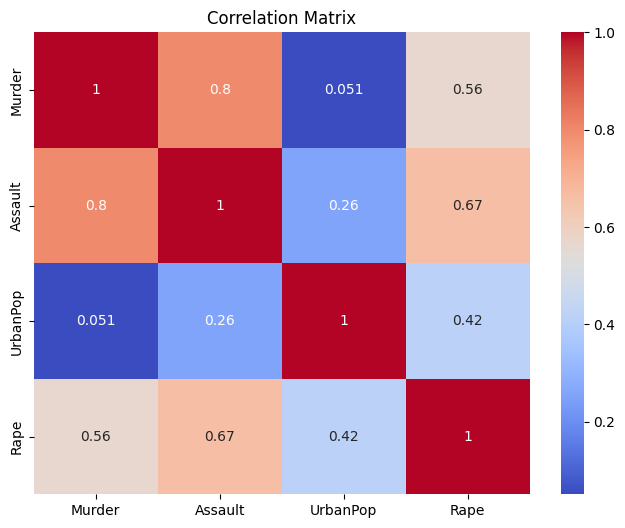

In [29]:
plt.figure(figsize=(8,6))

sns.heatmap(
    df[["Murder","Assault","UrbanPop","Rape"]].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")
plt.show()

### Observation

The correlation heatmap illustrates the strength and direction of the relationships between the four variables in the US Arrests dataset: **Murder**, **Assault**, **UrbanPop**, and **Rape**. Correlation coefficients range from **-1** to **1**, where values closer to **1** indicate a strong positive relationship, values closer to **-1** indicate a strong negative relationship, and values near **0** indicate little or no linear relationship.

The heatmap reveals a **strong positive correlation between Murder and Assault**, suggesting that states with higher murder rates also tend to have higher assault rates. This indicates that these two violent crime measures are closely associated within the dataset.

The relationships between **UrbanPop** and the crime variables appear to be weaker, implying that the percentage of the population living in urban areas has only a limited linear association with murder, assault, and rape rates. This suggests that urbanisation alone is not a strong predictor of crime levels.

The **Rape** variable exhibits a moderate positive correlation with both **Murder** and **Assault**, indicating that states with higher rates of these crimes often also report higher rape rates. However, these relationships are not as strong as the correlation observed between murder and assault.



Pairplot

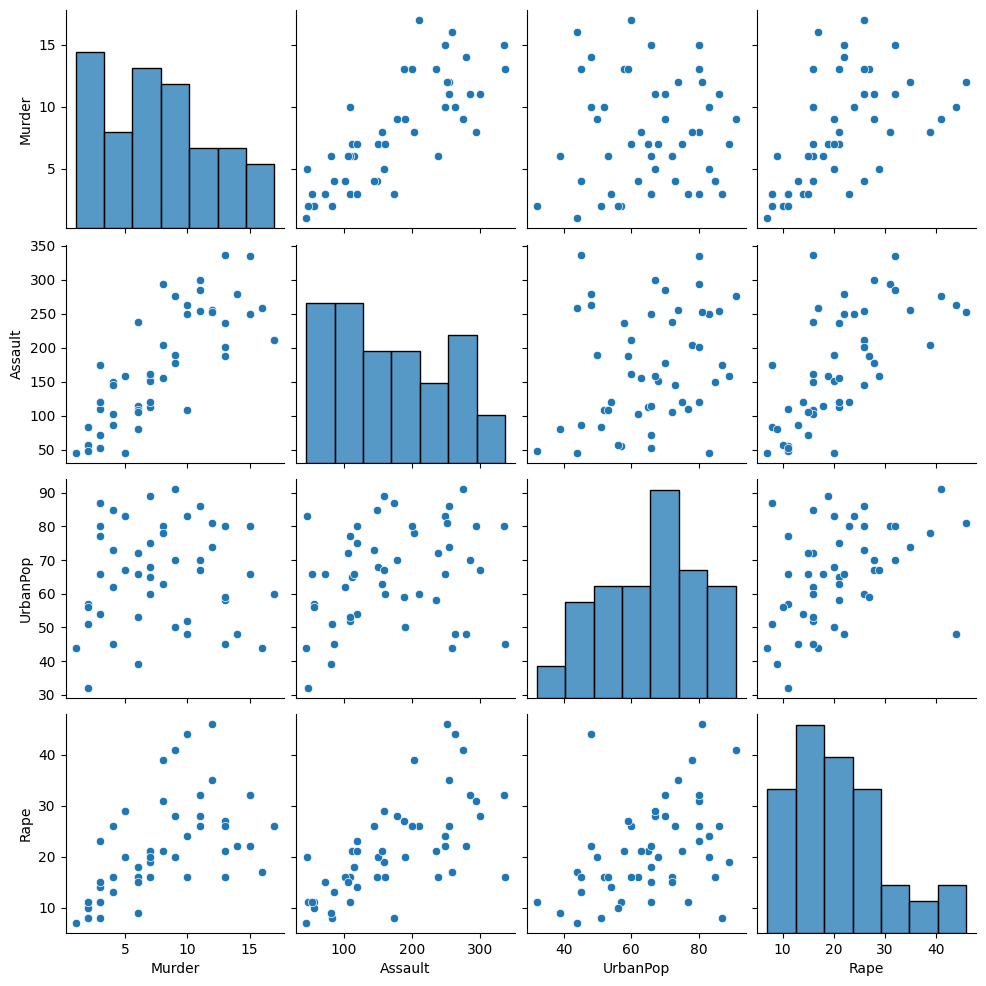

In [45]:
sns.pairplot(df[["Murder","Assault","UrbanPop","Rape"]])
plt.show()

### Observation

The pair plot provides a comprehensive visual overview of the relationships among the four variables in the US Arrests dataset: **Murder**, **Assault**, **UrbanPop**, and **Rape**. The diagonal plots display the distribution of each variable individually, while the off-diagonal scatter plots illustrate the pairwise relationships between every combination of variables.

The scatter plots indicate a **strong positive relationship between Murder and Assault**, as states with higher murder rates generally tend to have higher assault rates. There is also a moderate positive relationship between **Rape** and both **Murder** and **Assault**, suggesting that these crime variables tend to increase together in some states.

The relationships involving **UrbanPop** appear to be weaker and more dispersed, with no clear linear trend observed between urban population and the crime variables. This suggests that the percentage of the urban population alone is not a strong predictor of murder, assault, or rape rates.



20. The report was written by Lungelo Ndabambi